In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/tunguz/online-retail/Online_Retail.csv


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
file_path = '/kaggle/input/datasets/tunguz/online-retail/Online_Retail.csv'
df = pd.read_csv(file_path, encoding = 'ISO-8859-1')
#df.shape
print(f"成功讀取！總共有{df.shape[0]}筆交易紀錄，{df.shape[1]}個欄位。")
df.head(5)

成功讀取！總共有541909筆交易紀錄，8個欄位。


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/10 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/10 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/10 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/10 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/10 8:26,3.39,17850.0,United Kingdom


In [4]:
non_product_codes = [
    "POST","DOT","M","C2","D","S",
    "BANK CHARGES","AMAZONFEE","CRUK",
    "B","m"
]

In [5]:
df_clean = df[
    (~df["InvoiceNo"].astype(str).str.startswith("C")) &
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0) &
    (~df["StockCode"].isin(non_product_codes))
].copy()

In [6]:
df_clean["TotalPrice"] = df_clean["Quantity"] * df_clean["UnitPrice"]
df_clean["InvoiceDate"] = pd.to_datetime(df_clean["InvoiceDate"],
                                        format="%m/%d/%y %H:%M")

In [7]:
df_clean["YearMonth"] = df_clean["InvoiceDate"].dt.to_period("M").astype(str)
df_clean["Month"] = df_clean["InvoiceDate"].dt.month
df_clean["DayOfWeek_Num"] = df_clean["InvoiceDate"].dt.dayofweek  # 0=週一, 6=週日
df_clean["DayOfWeek"] = df_clean["InvoiceDate"].dt.day_name()
df_clean["Hour"] = df_clean["InvoiceDate"].dt.hour

In [8]:
display(df_clean)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice,YearMonth,Month,DayOfWeek_Num,DayOfWeek,Hour
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,2010-12,12,2,Wednesday,8
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12,12,2,Wednesday,8
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,2010-12,12,2,Wednesday,8
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12,12,2,Wednesday,8
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12,12,2,Wednesday,8
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France,10.20,2011-12,12,4,Friday,12
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France,12.60,2011-12,12,4,Friday,12
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60,2011-12,12,4,Friday,12
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60,2011-12,12,4,Friday,12


指標1：月度營收與 MoM 成長率（Month-over-Month，月增率）

看 Total_Revenue（絕對金額）：知道「哪幾個月賺最多錢」（例如 11 月營收衝到最高，代表是聖誕節批發備貨旺季）。

看 MoM 成長率（相對動能）：知道「哪一個月開始突然加速起飛」（例如 9 月的 MoM 突然大幅轉正暴衝），這能幫採購與倉儲部門抓出「旺季啟動的轉折點」，決定最晚必須在 8 月底前完成備貨。

In [9]:
monthly_sales = df_clean.groupby('YearMonth').agg(
    Total_Revenue=('TotalPrice', 'sum'),
    Order_Count=('InvoiceNo', 'nunique')
).reset_index()
monthly_sales

,YearMonth,Total_Revenue,Order_Count
0,2010-12,778008.360,1550
1,2011-01,671992.410,1081
2,2011-02,508952.870,1093
3,2011-03,691265.940,1440
4,2011-04,516309.791,1235
5,2011-05,741275.740,1668
6,2011-06,738876.880,1525
7,2011-07,689397.741,1452
8,2011-08,725605.160,1339
9,2011-09,1030500.361,1818


In [10]:
# MoM 成長率 (%)：(本月營收 - 上月營收) / 上月營收 * 100
monthly_sales["MoM_Growth(%)"] = (monthly_sales["Total_Revenue"].pct_change() * 100).round(2)

In [11]:
print("=== 月度營收與 MoM 成長率摘要表 ===")
display(monthly_sales)

=== 月度營收與 MoM 成長率摘要表 ===


,YearMonth,Total_Revenue,Order_Count,MoM_Growth(%)
0,2010-12,778008.360,1550,NaN
1,2011-01,671992.410,1081,-13.63
2,2011-02,508952.870,1093,-24.26
3,2011-03,691265.940,1440,35.82
4,2011-04,516309.791,1235,-25.31
5,2011-05,741275.740,1668,43.57
6,2011-06,738876.880,1525,-0.32
7,2011-07,689397.741,1452,-6.70
8,2011-08,725605.160,1339,5.25
9,2011-09,1030500.361,1818,42.02


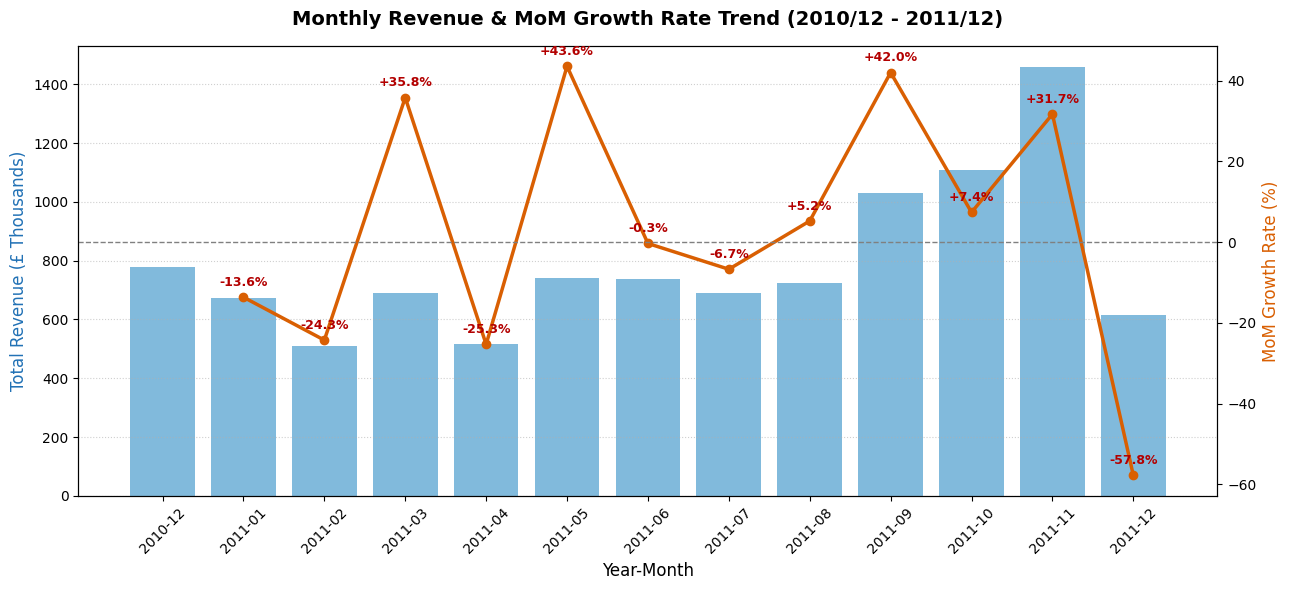

In [12]:
# 繪製雙軸圖：長條圖呈現月營收，折線圖呈現 MoM 成長率
fig, ax1 = plt.subplots(figsize=(13, 6))

# 左軸：月營收長條圖
bars = ax1.bar(monthly_sales["YearMonth"],
               monthly_sales["Total_Revenue"] / 1000, color="#6baed6",
               alpha=0.85, label="Monthly Revenue (£K)")
ax1.set_xlabel("Year-Month", fontsize=12)
ax1.set_ylabel("Total Revenue (£ Thousands)", fontsize=12, color="#2171b5")
ax1.tick_params(axis="x", rotation=45)
ax1.grid(axis="y", linestyle=":", alpha=0.6)

# 右軸：MoM 成長率折線圖
ax2 = ax1.twinx()
ax2.plot(monthly_sales["YearMonth"],
         monthly_sales["MoM_Growth(%)"],
         color="#d95f02", marker="o", linewidth=2.5, label="MoM Growth (%)")
ax2.axhline(0, color="gray", linestyle='--', linewidth=1)
ax2.set_ylabel("MoM Growth Rate (%)", fontsize=12, color="#d95f02")

# 標註 MoM 百分比數字
for i, txt in enumerate(monthly_sales["MoM_Growth(%)"]):
    if pd.notna(txt):
        ax2.annotate(f"{txt:+.1f}%", (monthly_sales["YearMonth"][i], txt),
                     xytext=(0, 8), textcoords="offset points", ha="center",
                     fontsize=9, fontweight="bold", color="#b30000")

plt.title("Monthly Revenue & MoM Growth Rate Trend (2010/12 - 2011/12)", fontsize=14, fontweight="bold", pad=15)
fig.tight_layout()
plt.savefig("monthly_revenue_mom.png", dpi=300, bbox_inches="tight")
plt.show()

指標 2：DayOfWeek × Hour 交叉分析

依照 DayOfWeek 與 Hour 交叉分組，同時計算每個時段的 不重複訂單數、總營收 與 平均單筆訂單營收（AOV）

In [13]:
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

In [14]:
time_grid = df_clean.groupby(["DayOfWeek", "Hour"]).agg(
    Unique_Orders=("InvoiceNo", "nunique"),
    Total_Revenue=("TotalPrice", "sum")
).reset_index()

In [15]:
# 計算該時段的「平均單筆訂單營收 (AOV)」
time_grid["Avg_Revenue_Per_Order"] = (time_grid["Total_Revenue"] / time_grid["Unique_Orders"]).round(2)

In [16]:
time_grid

,DayOfWeek,Hour,Unique_Orders,Total_Revenue,Avg_Revenue_Per_Order
0,Friday,7,6,16834.880,2805.81
1,Friday,8,121,51803.710,428.13
2,Friday,9,282,324803.741,1151.79
3,Friday,10,452,220591.240,488.03
4,Friday,11,397,201458.670,507.45
...,...,...,...,...,...
69,Wednesday,15,424,230944.040,544.68
70,Wednesday,16,262,122743.920,468.49
71,Wednesday,17,104,41281.810,396.94
72,Wednesday,19,2,3053.400,1526.70


In [17]:
print("=== 訂單密度最高 Top 5 黃金時段 ===")
display(time_grid.sort_values(by='Unique_Orders', ascending=False).head(5))

=== 訂單密度最高 Top 5 黃金時段 ===


,DayOfWeek,Hour,Unique_Orders,Total_Revenue,Avg_Revenue_Per_Order
66,Wednesday,12,626,289307.73,462.15
40,Thursday,12,592,284603.60,480.75
54,Tuesday,12,552,260861.62,472.58
67,Wednesday,13,508,230849.82,454.43
55,Tuesday,13,499,231769.50,464.47


In [18]:
# 轉成透視表 (Pivot Table) 準備畫熱力圖（Y軸為星期，X軸為小時）
orders_pivot = time_grid.pivot(index="DayOfWeek",
                               columns="Hour", values="Unique_Orders").reindex(day_order).fillna(0)
avg_rev_pivot = time_grid.pivot(index="DayOfWeek",
                                columns="Hour", values="Avg_Revenue_Per_Order").reindex(day_order).fillna(0)

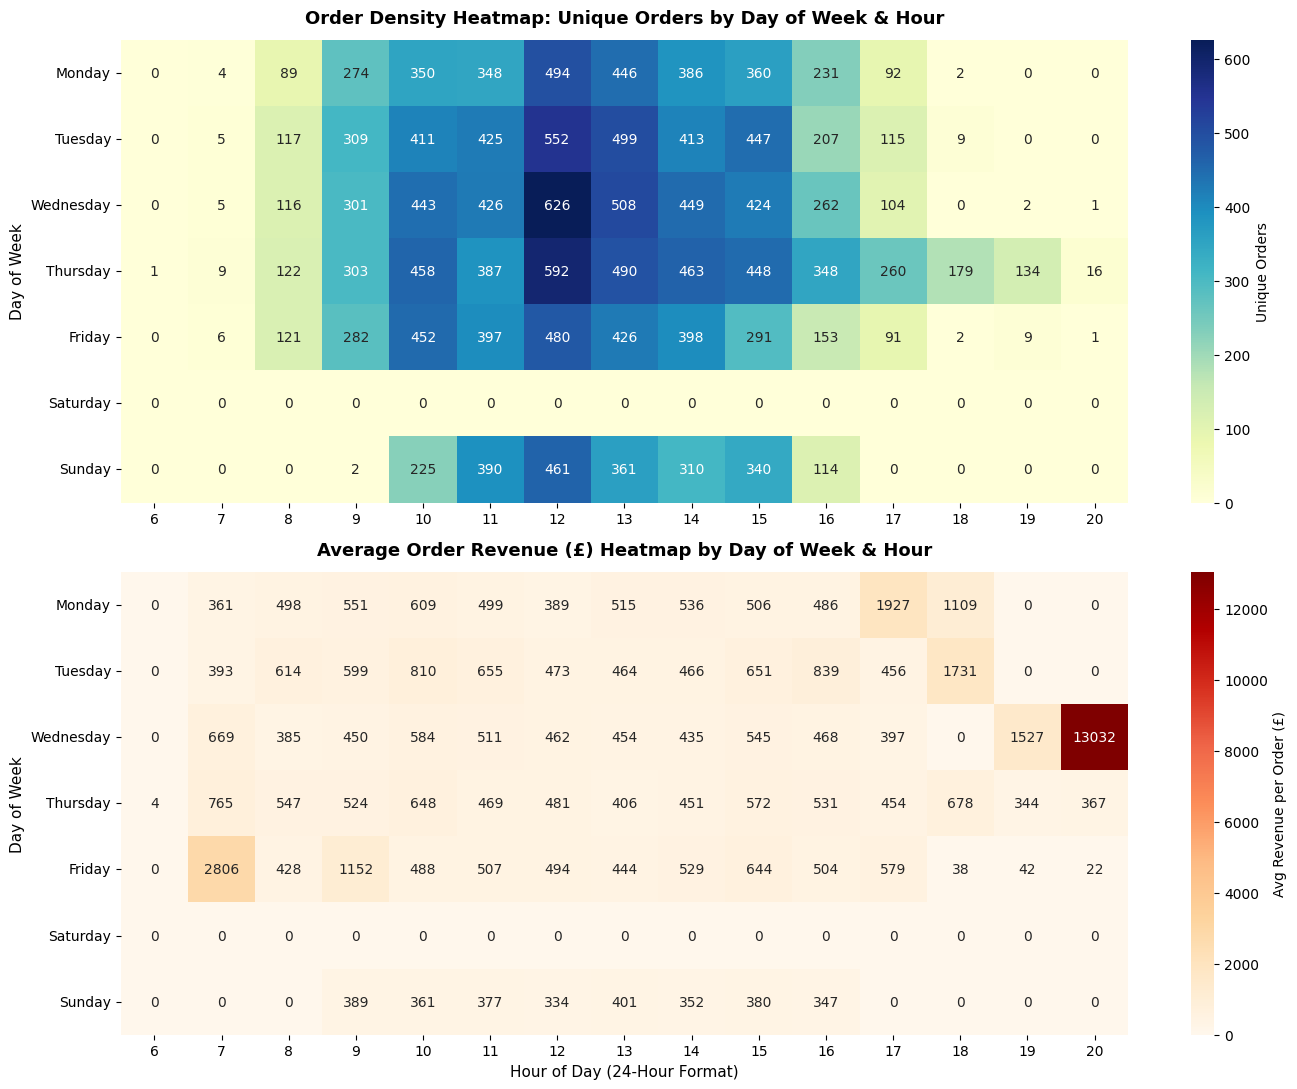

In [19]:
# 繪製雙熱力圖對比（上圖：不重複訂單數密度；下圖：平均單筆訂單營收）
fig, axes = plt.subplots(2, 1, figsize=(14, 11))

# 圖 A：每小時不重複訂單數熱力圖（客服排班與 EDM 推播點擊率指標）
sns.heatmap(
    orders_pivot,
    cmap='YlGnBu',
    annot=True,
    fmt='.0f',
    cbar_kws={'label': 'Unique Orders'},
    ax=axes[0]
)
axes[0].set_title('Order Density Heatmap: Unique Orders by Day of Week & Hour', fontsize=13, fontweight='bold', pad=12)
axes[0].set_xlabel('')
axes[0].set_ylabel('Day of Week', fontsize=11)

# 圖 B：每小時平均訂單營收熱力圖（大額批發進貨時段指標）
sns.heatmap(
    avg_rev_pivot,
    cmap='OrRd',
    annot=True,
    fmt='.0f',
    cbar_kws={'label': 'Avg Revenue per Order (£)'},
    ax=axes[1]
)
axes[1].set_title('Average Order Revenue (£) Heatmap by Day of Week & Hour', fontsize=13, fontweight='bold', pad=12)
axes[1].set_xlabel('Hour of Day (24-Hour Format)', fontsize=11)
axes[1].set_ylabel('Day of Week', fontsize=11)

plt.tight_layout()
plt.savefig('day_hour_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()